# Predicting the Men's March Madness Bracket

CIS4930 Introduction to Machine Learning: Term Project

Team: Lance, Sienna, Lincy, Pablo, Krish

1. Problem definition
2. Load the data
3. Data preparation
4. Exploratory data analysis
5. Project plan
6. Train / validation / test split
7. Models
8. Fit: overfitting or underfitting?
9. Next steps and timeline

## 1. Problem Definition

Question: Can machine learning predict men's NCAA tournament games better than just picking the higher seed?

| | |
|---|---|
| Task | Binary classification |
| One row | One tournament game (2003–2025) |
| Target | `TeamA_Win`: 1 if Team A won, 0 if Team B won (Team A = the team with the lower ID, so the label is about 50/50) |
| Features | 13 numbers, each one *Team A's regular-season stat minus Team B's* |
| Baseline | Always pick the higher seed |
| Metrics | Accuracy, log loss (how good the predicted probabilities are) and upsets correctly picked |

All features come from before the tournament, so nothing about the game being predicted leaks in.

## 2. Load the Data

Kaggle *March Machine Learning Mania 2026* (official NCAA results). Men's files only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_score, validation_curve
from sklearn.metrics import accuracy_score, log_loss

import warnings
warnings.filterwarnings("ignore")

SEED = 42
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
})

In [2]:
folder = "march-machine-learning-mania-2026/"

tourney = pd.read_csv(folder + "MNCAATourneyCompactResults.csv")     # tournament results
seeds   = pd.read_csv(folder + "MNCAATourneySeeds.csv")              # tournament seeds
season  = pd.read_csv(folder + "MRegularSeasonDetailedResults.csv")  # regular-season box scores
teams   = pd.read_csv(folder + "MTeams.csv")                         # team names
massey  = pd.read_csv(folder + "MMasseyOrdinals.csv")                # computer rankings

for name, frame in [("Tournament games", tourney), ("Seeds", seeds), ("Regular season games", season),
                    ("Teams", teams), ("Rankings", massey)]:
    print(f"{name:22} {frame.shape}")

Tournament games       (2585, 8)
Seeds                  (2694, 3)
Regular season games   (124529, 34)
Teams                  (381, 4)
Rankings               (5865001, 5)


In [3]:
tourney.head()

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT
0,1985,136,1116,63,1234,54,N,0
1,1985,136,1120,59,1345,58,N,0
2,1985,136,1207,68,1250,43,N,0
3,1985,136,1229,58,1425,55,N,0
4,1985,136,1242,49,1325,38,N,0


Each row is one tournament game: `WTeamID` won and `LTeamID` lost. The regular-season file has the same layout plus box score stats (`W...` = winner, `L...` = loser).

## 3. Data Preparation

### 3.1 Data quality

In [4]:
for name, frame in [("tourney", tourney), ("seeds", seeds), ("season", season), ("teams", teams), ("massey", massey)]:
    print(f"{name:8} missing values: {frame.isna().sum().sum()}   duplicates: {frame.duplicated().sum()}")

print("\nBox scores start in", season.Season.min(), "| no tournament in 2020:", 2020 not in tourney.Season.values)

tourney  missing values: 0   duplicates: 0
seeds    missing values: 0   duplicates: 0
season   missing values: 0   duplicates: 0
teams    missing values: 0   duplicates: 0
massey   missing values: 0   duplicates: 0

Box scores start in 2003 | no tournament in 2020: True


No missing values or duplicates. Box scores start in 2003, so we use tournaments from 2003 onward.

### 3.2 Team stats for each season

We average every team's regular-season games. Possessions (`FGA − OR + TO + 0.44·FTA`) let us measure points per 100 possessions, which compares fast and slow teams fairly.

In [5]:
w = pd.DataFrame({"Season": season.Season, "TeamID": season.WTeamID, "OppID": season.LTeamID, "Win": 1,
                  "Points": season.WScore, "OppPoints": season.LScore,
                  "FGM": season.WFGM, "FGA": season.WFGA, "FGM3": season.WFGM3, "FGA3": season.WFGA3,
                  "Reb": season.WOR + season.WDR, "TO": season.WTO,
                  "FTA": season.WFTA, "OR": season.WOR,
                  "OppFGA": season.LFGA, "OppFTA": season.LFTA, "OppOR": season.LOR, "OppTO": season.LTO})

l = pd.DataFrame({"Season": season.Season, "TeamID": season.LTeamID, "OppID": season.WTeamID, "Win": 0,
                  "Points": season.LScore, "OppPoints": season.WScore,
                  "FGM": season.LFGM, "FGA": season.LFGA, "FGM3": season.LFGM3, "FGA3": season.LFGA3,
                  "Reb": season.LOR + season.LDR, "TO": season.LTO,
                  "FTA": season.LFTA, "OR": season.LOR,
                  "OppFGA": season.WFGA, "OppFTA": season.WFTA, "OppOR": season.WOR, "OppTO": season.WTO})

games = pd.concat([w, l])
games["Poss"]    = games.FGA - games.OR + games.TO + 0.44 * games.FTA
games["OppPoss"] = games.OppFGA - games.OppOR + games.OppTO + 0.44 * games.OppFTA

t = games.groupby(["Season", "TeamID"]).sum()
n_games = games.groupby(["Season", "TeamID"]).size()

team = pd.DataFrame({
    "WinPct":  t.Win / n_games,
    "PPG":     t.Points / n_games,
    "OppPPG":  t.OppPoints / n_games,
    "FG_Pct":  t.FGM / t.FGA,
    "FG3_Pct": t.FGM3 / t.FGA3,
    "Reb":     t.Reb / n_games,
    "TO":      t.TO / n_games,
    "OffEff":  100 * t.Points / t.Poss,        # points scored per 100 possessions
    "DefEff":  100 * t.OppPoints / t.OppPoss,  # points allowed per 100 possessions
}).reset_index()
team["PointDiff"] = team.PPG - team.OppPPG

# Strength of schedule: average win % of the opponents each team played
opp_win = team.set_index(["Season", "TeamID"]).WinPct.rename("OppWinPct")
sos = games.join(opp_win, on=["Season", "OppID"]).groupby(["Season", "TeamID"]).OppWinPct.mean()
team = team.join(sos.rename("SOS"), on=["Season", "TeamID"])

# Pomeroy ranking: the last one published before the tournament (day 133)
pom = massey[(massey.SystemName == "POM") & (massey.RankingDayNum <= 133)]
pom = pom.sort_values("RankingDayNum").groupby(["Season", "TeamID"]).OrdinalRank.last()
team = team.join(pom.rename("Rank_POM"), on=["Season", "TeamID"])

# Seed: "W01" -> 1
seeds["Seed"] = seeds.Seed.str[1:3].astype(int)
team = team.merge(seeds, on=["Season", "TeamID"], how="left")
team.dropna(subset=["Seed"]).head()

,Season,TeamID,WinPct,PPG,OppPPG,FG_Pct,FG3_Pct,Reb,TO,OffEff,DefEff,PointDiff,SOS,Rank_POM,Seed
2,2003,1104,0.607143,69.285714,65.000000,0.420362,0.320144,37.500000,13.285714,104.817272,98.474191,4.285714,0.572492,33.0,10.0
9,2003,1112,0.892857,85.214286,70.250000,0.461413,0.350534,42.821429,14.785714,111.651848,92.163955,14.964286,0.551868,3.0,1.0
10,2003,1113,0.620690,75.965517,69.172414,0.478182,0.317808,37.000000,14.000000,110.514699,99.960136,6.793103,0.581878,32.0,10.0
16,2003,1120,0.633333,70.100000,65.566667,0.469835,0.344898,34.500000,15.900000,104.084178,97.172272,4.533333,0.572247,45.0,10.0
17,2003,1122,0.740741,69.703704,67.703704,0.452347,0.349138,34.851852,15.222222,103.684605,100.563331,2.000000,0.461247,123.0,13.0


### 3.3 One row per tournament game

Put Team A and Team B side by side and take the difference of each stat.

In [6]:
df = tourney[tourney.Season >= 2003].copy()
df["TeamA"] = df[["WTeamID", "LTeamID"]].min(axis=1)
df["TeamB"] = df[["WTeamID", "LTeamID"]].max(axis=1)
df["TeamA_Win"] = (df.WTeamID == df.TeamA).astype(int)

df = df.merge(team.add_prefix("A_"), left_on=["Season", "TeamA"], right_on=["A_Season", "A_TeamID"])
df = df.merge(team.add_prefix("B_"), left_on=["Season", "TeamB"], right_on=["B_Season", "B_TeamID"])

features = ["Seed", "WinPct", "PointDiff", "PPG", "OppPPG", "FG_Pct", "FG3_Pct", "Reb", "TO",
            "OffEff", "DefEff", "SOS", "Rank_POM"]
for f in features:
    df[f + "_Diff"] = df["A_" + f] - df["B_" + f]
feature_cols = [f + "_Diff" for f in features]

names = teams.set_index("TeamID").TeamName
df["TeamA_Name"] = df.TeamA.map(names)
df["TeamB_Name"] = df.TeamB.map(names)

# Upset = the worse (higher-number) seed won. Games between equal seeds can't be upsets.
df["Upset"] = np.where(df.Seed_Diff == 0, np.nan,
                       ((df.Seed_Diff > 0) == (df.TeamA_Win == 1)).astype(float))

data = df[["Season", "TeamA_Name", "TeamB_Name", "A_Seed", "B_Seed"] + feature_cols
          + ["Upset", "TeamA_Win"]].reset_index(drop=True)

print("Games:", len(data), "| Features:", len(feature_cols),
      "| Missing values:", data[feature_cols].isna().sum().sum())
data.head()

Games: 1449 | Features: 13 | Missing values: 0


,Season,TeamA_Name,TeamB_Name,A_Seed,B_Seed,Seed_Diff,WinPct_Diff,PointDiff_Diff,PPG_Diff,OppPPG_Diff,FG_Pct_Diff,FG3_Pct_Diff,Reb_Diff,TO_Diff,OffEff_Diff,DefEff_Diff,SOS_Diff,Rank_POM_Diff,Upset,TeamA_Win
0,2003,TX Southern,UNC Asheville,16.0,16.0,0.0,0.151724,9.208046,1.593103,-7.614943,0.018262,-0.039433,2.518391,-0.973563,2.653173,-12.376875,-0.104891,-5.0,NaN,0
1,2003,Arizona,Vermont,1.0,16.0,-15.0,0.237685,10.309113,17.421182,7.112069,0.016969,0.009777,4.131773,0.716749,8.258702,-4.352797,0.114559,-141.0,0.0,1
2,2003,Arizona St,Memphis,10.0,7.0,3.0,-0.172414,-1.896552,1.448276,3.344828,0.040251,-0.030989,-3.034483,0.206897,3.754363,5.522507,0.065246,12.0,1.0,1
3,2003,C Michigan,Creighton,11.0,6.0,5.0,-0.085684,-8.805643,0.102403,8.908046,0.005763,-0.008284,-0.198537,4.877743,-4.162118,8.874154,-0.005888,23.0,1.0,1
4,2003,California,NC State,8.0,9.0,-1.0,0.124138,0.324138,2.082759,1.758621,0.009399,0.022444,3.854023,-0.027586,-2.338371,-2.831146,-0.031658,-8.0,0.0,1


| Feature (Team A − Team B) | Meaning |
|---|---|
| `Seed_Diff` | Tournament seed (1 = best) |
| `WinPct_Diff` | Regular-season win % |
| `PointDiff_Diff` | Average scoring margin |
| `PPG_Diff` / `OppPPG_Diff` | Points scored / allowed per game |
| `FG_Pct_Diff` / `FG3_Pct_Diff` | Field goal % / 3-point % |
| `Reb_Diff` / `TO_Diff` | Rebounds / turnovers per game |
| `OffEff_Diff` / `DefEff_Diff` | Points scored / allowed per 100 possessions |
| `SOS_Diff` | Strength of schedule (average win % of opponents) |
| `Rank_POM_Diff` | Pomeroy computer ranking before the tournament (1 = best) |

## 4. Exploratory Data Analysis

### 4.1 The target is balanced

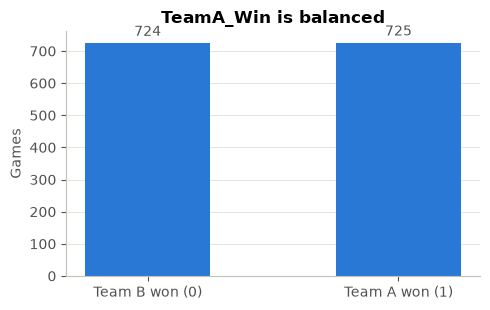

In [7]:
counts = data.TeamA_Win.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(["Team B won (0)", "Team A won (1)"], counts.values, color=BLUE, width=0.5)
ax.bar_label(bars, padding=3, color="#52514e")
ax.set_ylabel("Games")
ax.set_title("TeamA_Win is balanced")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 4.2 How often does the higher seed win?

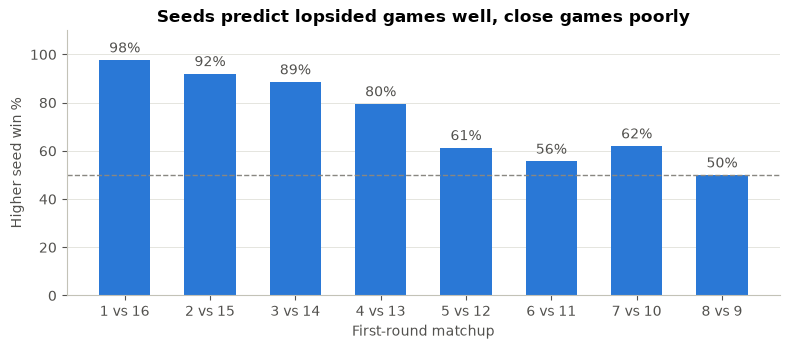

Overall, the higher seed wins 71.3% of games


In [28]:
first_round = data[(data.A_Seed + data.B_Seed) == 17].copy()
first_round["Matchup"] = first_round[["A_Seed", "B_Seed"]].min(axis=1).astype(int)
by_matchup = (1 - first_round.groupby("Matchup").Upset.mean()) * 100
labels = [f"{s} vs {17 - s}" for s in by_matchup.index]

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(labels, by_matchup.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=3, color="#52514e")
ax.axhline(50, color=GRAY, lw=1, ls="--")
ax.set_ylim(0, 110)
ax.set_ylabel("Higher seed win %")
ax.set_xlabel("First-round matchup")
ax.set_title("Seeds predict lopsided games well, close games poorly")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Overall, the higher seed wins {(1 - data.Upset.mean()) * 100:.1f}% of games")

### 4.3 Upsets by year

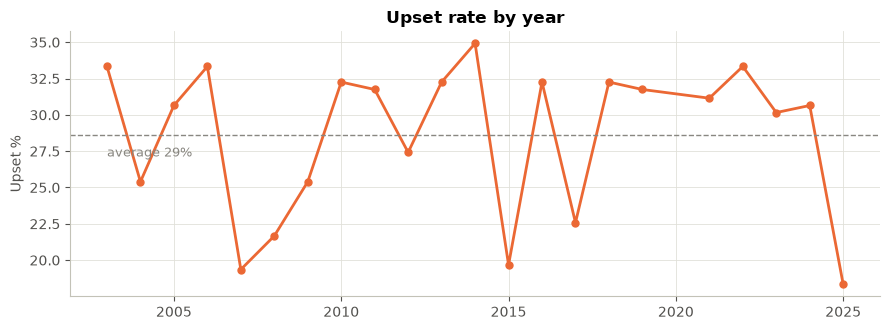

In [9]:
by_year = data.groupby("Season").Upset.mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(by_year.index, by_year.values, color=ORANGE, lw=2, marker="o", ms=5)
ax.axhline(by_year.mean(), color=GRAY, lw=1, ls="--")
ax.text(2003, by_year.mean() - 1.5, f"average {by_year.mean():.0f}%", color=GRAY, fontsize=9)
ax.set_ylabel("Upset %")
ax.set_title("Upset rate by year")
plt.tight_layout()
plt.show()

### 4.4 Feature distributions

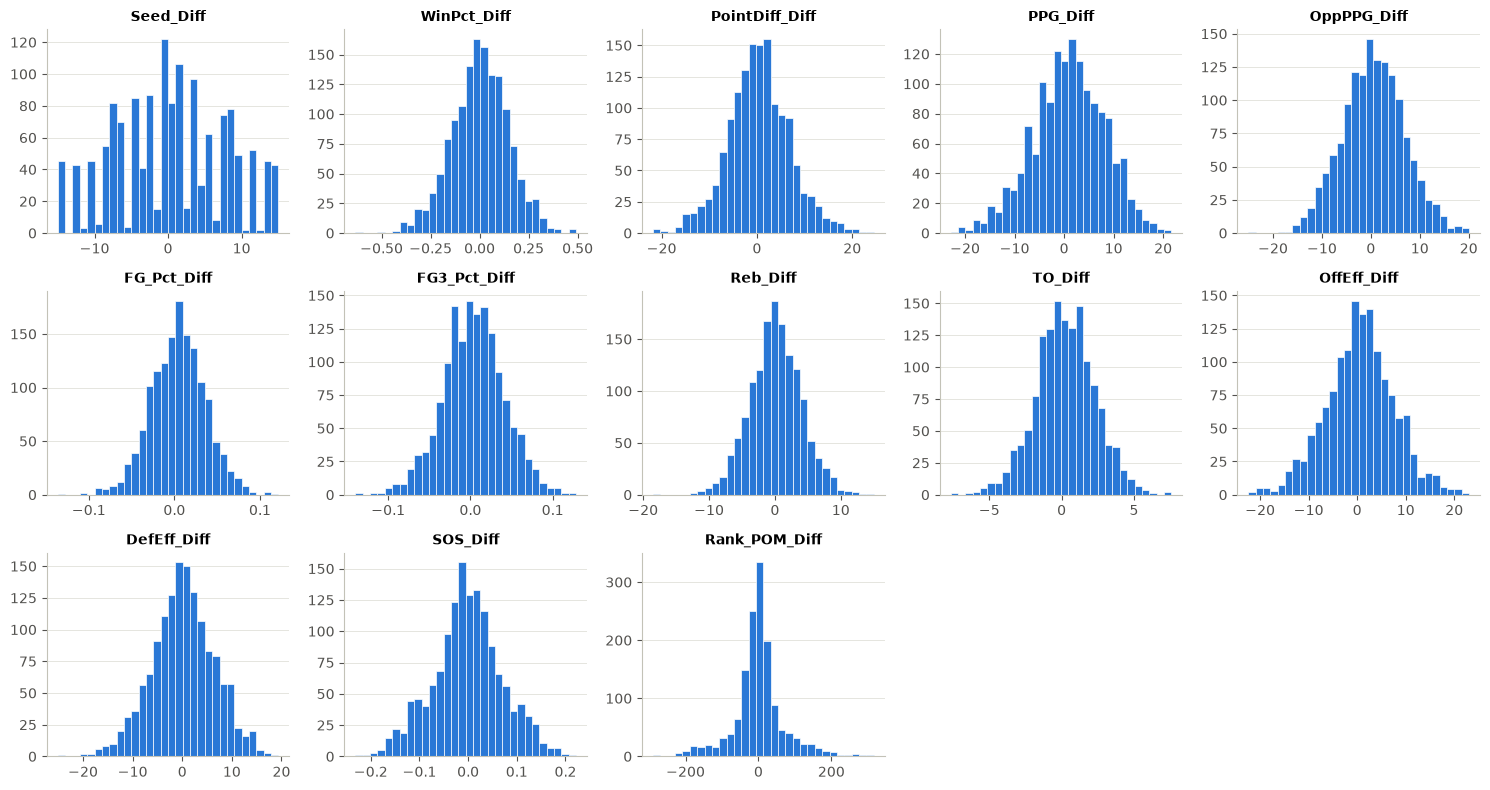

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, col in zip(axes.flat, feature_cols):
    ax.hist(data[col], bins=30, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(feature_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.5 Which features relate to winning?

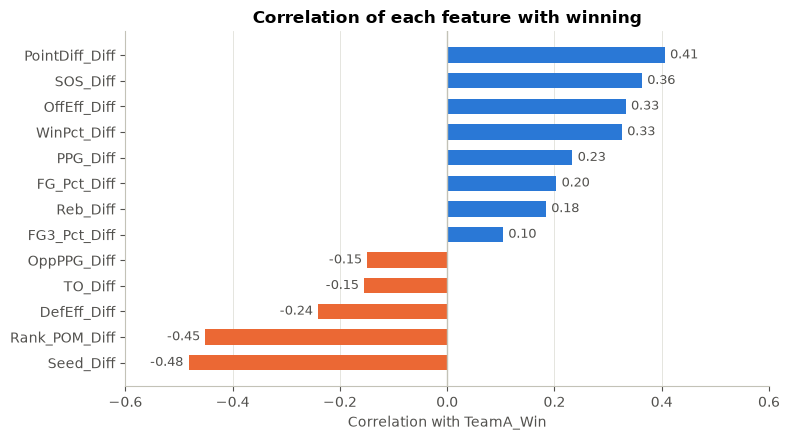

In [11]:
corr_target = data[feature_cols].corrwith(data.TeamA_Win).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(corr_target.index, corr_target.values, height=0.6,
        color=[ORANGE if v < 0 else BLUE for v in corr_target.values])
ax.axvline(0, color="#c3c2b7", lw=1)
for i, v in enumerate(corr_target.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color="#52514e")
ax.set_xlim(-0.6, 0.6)
ax.set_xlabel("Correlation with TeamA_Win")
ax.set_title("Correlation of each feature with winning")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 4.6 Correlation between features

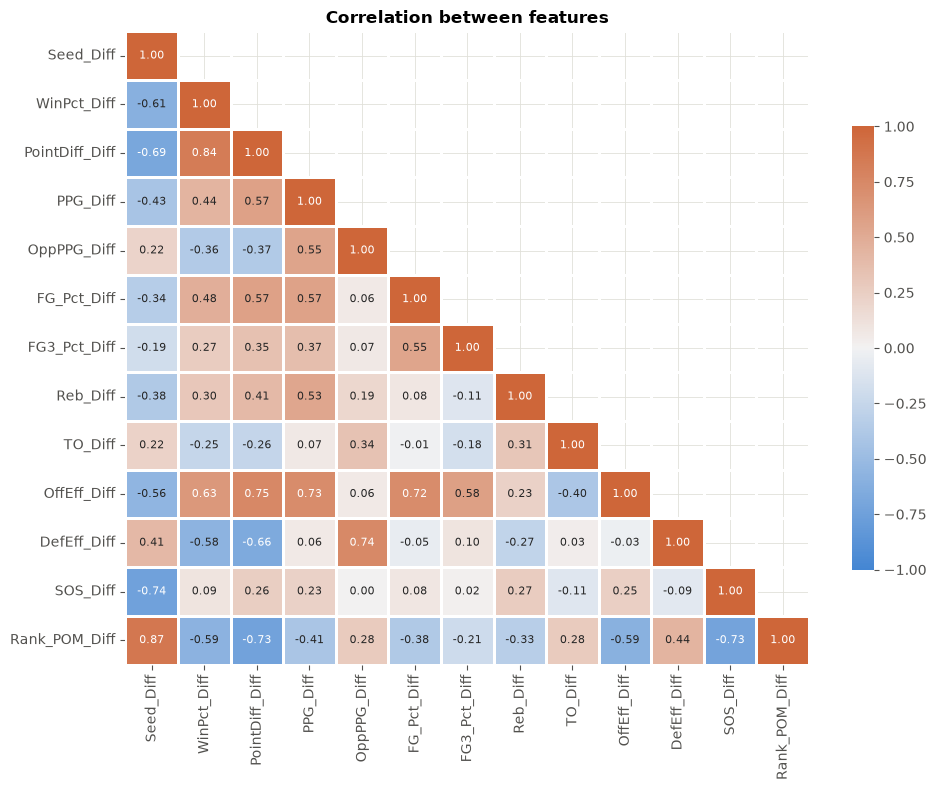

In [12]:
corr = data[feature_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = sns.diverging_palette(250, 25, s=80, l=55, center="light", as_cmap=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation between features")
plt.tight_layout()
plt.show()

### 4.7 Outliers

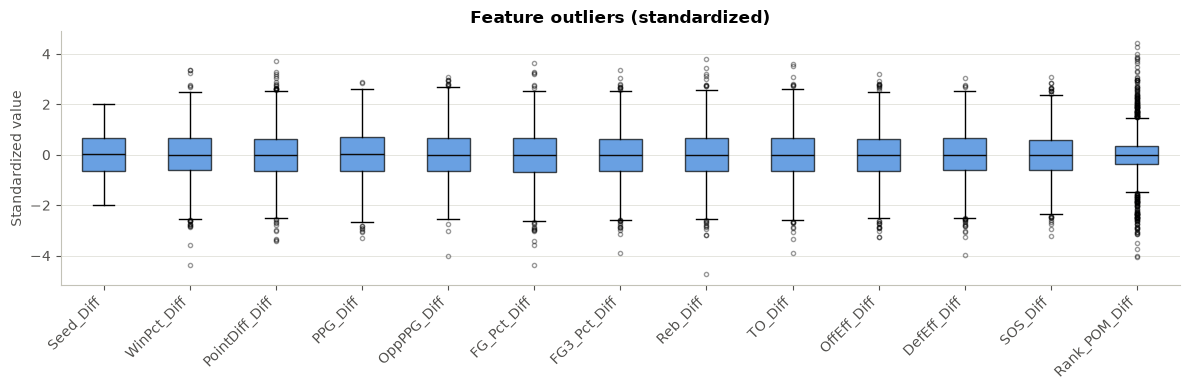

,Season,TeamA_Name,A_Seed,TeamB_Name,B_Seed,PointDiff_Diff,TeamA_Win
922,2017,Gonzaga,1.0,S Dakota St,16.0,24.486742,1
790,2015,Hampton,16.0,Kentucky,1.0,-21.789661,0
155,2005,North Carolina,1.0,Oakland,16.0,21.654060,1


In [13]:
z = (data[feature_cols] - data[feature_cols].mean()) / data[feature_cols].std()

fig, ax = plt.subplots(figsize=(12, 4))
bp = ax.boxplot([z[c] for c in feature_cols], widths=0.5, patch_artist=True,
                medianprops=dict(color="#0b0b0b"), flierprops=dict(marker="o", ms=3, alpha=0.4))
for patch in bp["boxes"]:
    patch.set_facecolor(BLUE); patch.set_alpha(0.7)
ax.set_xticks(range(1, len(feature_cols) + 1), feature_cols, rotation=45, ha="right")
ax.set_ylabel("Standardized value")
ax.set_title("Feature outliers (standardized)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

cols = ["Season", "TeamA_Name", "A_Seed", "TeamB_Name", "B_Seed", "PointDiff_Diff", "TeamA_Win"]
data.loc[data.PointDiff_Diff.abs().sort_values(ascending=False).index[:3], cols]



### 4.8 EDA summary
- 1,449 games, 13 features, no missing values, balanced target.
- Baseline to beat: the higher seed wins 71%. Seeds struggle in close matchups.
- Upsets (29%) vary a lot by year, so we evaluate across many seasons.
- Overall-strength features (seed, rank, point differential, schedule) matter most. Several features overlap.
- Features need scaling. Outliers are real and kept.

## 5. Project Plan

| Step | Plan |
|---|---|
| Split | By season: train 2003–2018, validate 2019 & 2021, test 2022–2025 |
| Models | Seed baseline, logistic regression, random forest, KNN, gradient boosting |
| Evaluation | Accuracy, log loss, upsets correctly picked, correct picks in a full bracket |


## 6. Train / Validation / Test Split

We split by season, not randomly, to copy the real task: learn from past tournaments and predict a new one.

| Set | Seasons | Used for |
|---|---|---|
| Train | 2003–2018 | Fitting and tuning models |
| Validation | 2019, 2021 | Comparing models |
| Test | 2022–2025 | Final results only (not used yet) |

To tune models we also use cross-validation (CV) on the training seasons: split the 16 seasons into 5 groups, train on 4 and test on the 5th, rotate, and average. That gives a more reliable score than 133 validation games alone.

In [ ]:
train = data[data.Season <= 2018]
val   = data[data.Season.isin([2019, 2021])]
test  = data[data.Season >= 2022]

X_train, y_train = train[feature_cols], train.TeamA_Win
X_val,   y_val   = val[feature_cols],   val.TeamA_Win

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s = scaler.transform(X_train), scaler.transform(X_val)

cv = GroupKFold(n_splits=5)     
groups = train.Season

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:10} {len(part):5} games")

Train       1048 games
Validation   133 games
Test         268 games


## 7. Models

In [15]:
results = {}

def evaluate(name, p_train, p_val, cv_acc=np.nan):
    """p_train / p_val = predicted probability that Team A wins."""
    pred_val = (p_val >= 0.5).astype(int)

    # Upsets: games where the model picked the worse seed
    has_fav = val.Seed_Diff != 0
    picked_upset = has_fav & ((pred_val == 1) == (val.Seed_Diff > 0))
    real_upset = val.Upset == 1

    results[name] = {
        "Train acc": accuracy_score(y_train, p_train >= 0.5),
        "CV acc": cv_acc,
        "Val acc": accuracy_score(y_val, pred_val),
        "Val log loss": log_loss(y_val, np.clip(p_val, 0.001, 0.999)),
        "Upsets picked": int(picked_upset.sum()),
        "Upsets correct": int((picked_upset & real_upset).sum()),
        "Real upsets": int(real_upset.sum()),
    }
    return pd.Series(results[name]).round(3)

### 7.1 Seed baseline

Pick the higher seed. If both teams have the same seed, give each 50%.

In [16]:
def seed_baseline(frame):
    return np.where(frame.Seed_Diff < 0, 1.0, np.where(frame.Seed_Diff > 0, 0.0, 0.5))

evaluate("Seed baseline", seed_baseline(train), seed_baseline(val))

Train acc          0.700
CV acc               NaN
Val acc            0.684
Val log loss       2.073
Upsets picked      0.000
Upsets correct     0.000
Real upsets       39.000
dtype: float64

### 7.2 Logistic regression

A simple linear model that outputs a win probability. We tune C (how strongly the model is kept simple) with cross-validation.

In [17]:
lr_search = GridSearchCV(LogisticRegression(max_iter=2000), {"C": np.logspace(-3, 2, 11)},
                         cv=cv, scoring="neg_log_loss")
lr_search.fit(X_train_s, y_train, groups=groups)
lr = lr_search.best_estimator_
lr_cv = cross_val_score(lr, X_train_s, y_train, groups=groups, cv=cv).mean()

print("Best C:", round(lr.C, 3))
evaluate("Logistic regression", lr.predict_proba(X_train_s)[:, 1], lr.predict_proba(X_val_s)[:, 1], lr_cv)

Best C: 0.032


Train acc          0.715
CV acc             0.707
Val acc            0.677
Val log loss       0.571
Upsets picked      8.000
Upsets correct     3.000
Real upsets       39.000
dtype: float64

### 7.3 Random forest

Many decision trees voting together. It can capture non-linear patterns but can also memorize the training data, so we tune tree depth and minimum leaf size.

In [ ]:
rf_search = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                         {"max_depth": [2, 3, 4, 6, 8, None], "min_samples_leaf": [1, 5, 20, 50]},
                         cv=cv, scoring="neg_log_loss")
rf_search.fit(X_train, y_train, groups=groups)
rf = rf_search.best_estimator_
rf_cv = cross_val_score(rf, X_train, y_train, groups=groups, cv=cv).mean()

print("Best settings:", rf_search.best_params_)
evaluate("Random forest", rf.predict_proba(X_train)[:, 1], rf.predict_proba(X_val)[:, 1], rf_cv)

Best settings: {'max_depth': 6, 'min_samples_leaf': 20}


Train acc          0.765
CV acc             0.704
Val acc            0.707
Val log loss       0.568
Upsets picked      7.000
Upsets correct     4.000
Real upsets       39.000
dtype: float64

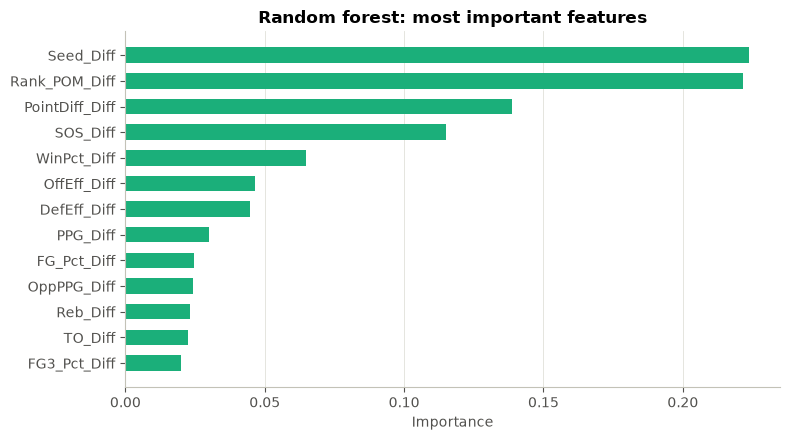

In [19]:
importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance.values, color=AQUA, height=0.6)
ax.set_xlabel("Importance")
ax.set_title("Random forest: most important features")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Seed and Pomeroy rank matter most, followed by point differential and strength of schedule. This matches the EDA.

### 7.4 Results

In [20]:
results_df = pd.DataFrame(results).T
results_df.round(3)

,Train acc,CV acc,Val acc,Val log loss,Upsets picked,Upsets correct,Real upsets
Seed baseline,0.700,NaN,0.684,2.073,0.0,0.0,39.0
Logistic regression,0.715,0.707,0.677,0.571,8.0,3.0,39.0
Random forest,0.765,0.704,0.707,0.568,7.0,4.0,39.0


What the results show
- Accuracy: all three are about 70%. On validation, random forest is best (70.7% vs. 68.4% for seeds), but that is only 3 more games out of 133, so it is not a clear win yet.
- Probabilities: the models are much better (log loss 0.57 vs. 2.07, lower is better). The seed baseline is 100% sure of every pick, so every upset costs it heavily. The models give realistic chances, which we need for the bracket.
- Upsets: seeds never pick an upset. The random forest picked 7 and got 4 right, but missed most of the 39 real upsets. Picking upsets is the main thing to improve.

## 8. Fit: Overfitting or Underfitting

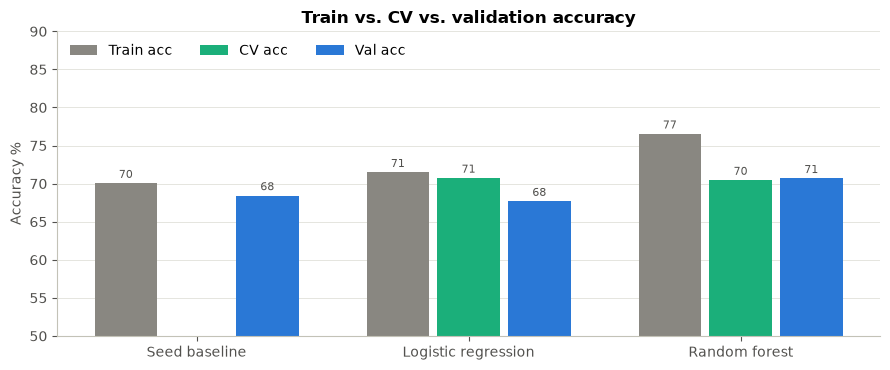

In [21]:
plot_df = results_df[["Train acc", "CV acc", "Val acc"]] * 100
x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (col, c) in enumerate(zip(plot_df.columns, [GRAY, AQUA, BLUE])):
    bars = ax.bar(x + (i - 1) * 0.26, plot_df[col].values, 0.23, color=c, label=col)
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8, color="#52514e")
ax.set_xticks(x, plot_df.index)
ax.set_ylim(50, 90)
ax.set_ylabel("Accuracy %")
ax.set_title("Train vs. CV vs. validation accuracy")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Next, we change how complex each model is and watch train vs. CV accuracy.

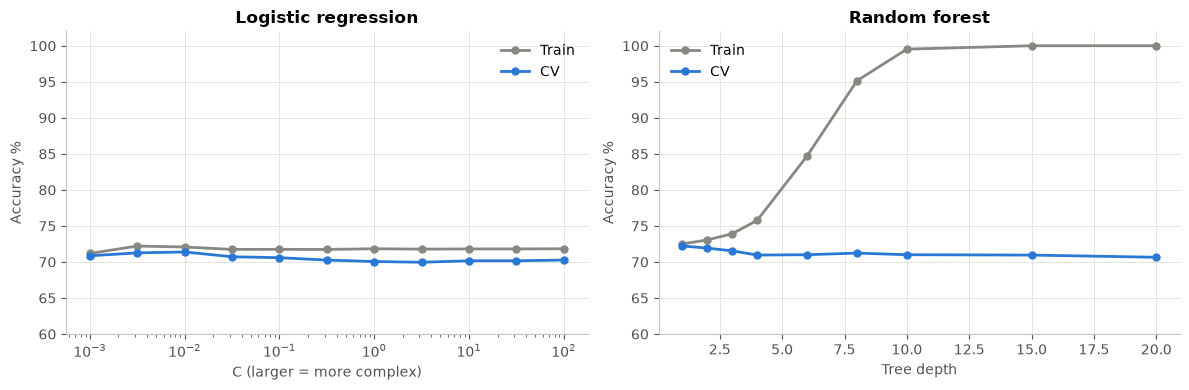

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

C_range = np.logspace(-3, 2, 11)
tr, va = validation_curve(LogisticRegression(max_iter=2000), X_train_s, y_train, groups=groups,
                          param_name="C", param_range=C_range, cv=cv)
axes[0].semilogx(C_range, tr.mean(1) * 100, color=GRAY, lw=2, marker="o", ms=5, label="Train")
axes[0].semilogx(C_range, va.mean(1) * 100, color=BLUE, lw=2, marker="o", ms=5, label="CV")
axes[0].set_xlabel("C (larger = more complex)")
axes[0].set_title("Logistic regression")
axes[0].set_ylim(60, 102)

depths = [1, 2, 3, 4, 6, 8, 10, 15, 20]
tr, va = validation_curve(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                          X_train, y_train, groups=groups, param_name="max_depth", param_range=depths, cv=cv)
axes[1].plot(depths, tr.mean(1) * 100, color=GRAY, lw=2, marker="o", ms=5, label="Train")
axes[1].plot(depths, va.mean(1) * 100, color=BLUE, lw=2, marker="o", ms=5, label="CV")
axes[1].set_xlabel("Tree depth")
axes[1].set_title("Random forest")
axes[1].set_ylim(60, 102)

for ax in axes:
    ax.set_ylabel("Accuracy %")
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Diagnosis

| Model | What the charts show | Verdict |
|---|---|---|
| Logistic regression | Train and CV stay within about 1 point at every setting | Good fit, no overfitting. It levels off around 71%, limited by the information in the features |
| Random forest | Deeper trees reach 100% on training data while CV stays at 71% | Overfits if trees are too deep. Tuning keeps it at depth 6 (77% train vs. 70% CV, a small gap) |

## 9. Next Steps and Timeline

Improvements based on results
1. Remove overlapping features (e.g. keep point differential, drop win %) to make models simpler.
2. Pick more upsets: pick the underdog when the model gives it a high enough chance, tuned with CV.
3. Bracket simulation: score models on full brackets, not just single games.

Remaining work

| Phase | Tasks |
|---|---|
| 1. Models | KNN |
| | Gradient boosting |
| | Logistic regression feature selection |
| | Team-swap data, test extra features |
| 2. Evaluation | Bracket simulation |
| | Upset picking and evaluation for all models |
| | Choose final models |
| 3. Final | Final test on 2022–2025 |
| | Report, presentation, cleanup |

LR with polynomial terms

Neural Network with keras (2-3 networks)

Hidden layers/number of neurons/batch normalization

Add more features (15-20 features)

Investigation of COVID years

More data exploration

Show Testing Accuracy